# Computational Techniques for Paleoclimate Research

## LiPD data format | PCA and EOF | Coral proxies and ENSO | Power spectra |

**MPhil in Past and Future Climates, University of Cambridge – Methods 02, Wednesday 21 October 2026**

---

This practical works with real proxy data from start to finish. We open the **CoralHydro2k** collection of coral records, stored in the Linked Paleo Data (**LiPD**) format, and select the long coral δ¹⁸O records. We then use **Principal Component Analysis (PCA)** to find the main pattern shared by the corals, and **Empirical Orthogonal Function (EOF)** analysis to find the main pattern in observed sea-surface temperature (SST), and test whether both record the **El Niño–Southern Oscillation (ENSO)**. Finally, **power spectra** show at which periods the two signals vary, and how far a short record lets us trust a spectral peak.

### Aims and learning outcomes

By the end of this practical you should be able to:

* open a LiPD collection and filter its records by variable, region and time span;
* prepare proxy time series for multivariate analysis (detrend, seasonal mean, common time axis, standardise);
* run a PCA on proxy records and an EOF analysis on a gridded field, and say what a mode, a loading and a principal component are;
* compute a power spectrum and test its peaks against red noise, and say what a "significant" peak in a short record can and cannot show;
* judge whether a proxy network captures a known climate mode, and name the main limits of that comparison.

---

Main libraries: [pyleoclim](https://pyleoclim-util.readthedocs.io/) and [pylipd](https://pylipd.readthedocs.io/) (paleo data), [pandas](https://pandas.pydata.org/) (tables), [xarray](https://docs.xarray.dev/) (gridded netCDF data), [xeofs](https://xeofs.readthedocs.io/) (EOF analysis), [scipy](https://docs.scipy.org/doc/scipy/reference/signal.html) (spectra), [matplotlib](https://matplotlib.org/) and [cartopy](https://cartopy.readthedocs.io/) (plots and maps).

**How to use this notebook:** run the cells from top to bottom (`Shift + Enter`). Each code cell has a short note above it saying what it does and why. You do not need to write code from scratch: the *Your turn* box asks you to change one or two words.

Instructor: Francesco Muschitiello (fm476), October 2026.

---

### Setup: import the libraries

We load every library we need once, here at the top. We also hide a few harmless "this will change in a future version" warnings that the libraries print, so the output stays readable (real errors are still shown).

In [ ]:
import warnings
from pathlib import Path

import numpy as np                      # numbers and arrays
import pandas as pd                     # tables
import xarray as xr                     # gridded (netCDF) data
import matplotlib.pyplot as plt         # plots
import cartopy.crs as ccrs              # map projections
import cartopy.feature as cfeature      # land and coastlines
from cartopy.util import add_cyclic_point  # closes the gap at the 0/360 longitude seam
from scipy import stats                 # correlation with a p-value
from scipy.signal import periodogram    # power spectra

from pylipd.lipd import LiPD            # reads LiPD files
import pyleoclim as pyleo               # paleo time series tools (incl. PCA)
import xeofs as xe                      # EOF analysis of gridded data

# Hide only "future version" style warnings coming from the libraries, not real errors
for lib in ["pyleoclim", "pylipd", "xeofs", "xarray", "pandas", "cartopy"]:
    warnings.filterwarnings("ignore", category=FutureWarning, module=lib)
    warnings.filterwarnings("ignore", category=DeprecationWarning, module=lib)
    warnings.filterwarnings("ignore", category=PendingDeprecationWarning, module=lib)

# Readable, consistent figures
plt.rcParams.update({"font.size": 12, "axes.titlesize": 13, "figure.dpi": 100})

### Check that the data are found

A quick check that the notebook can see the data. For a full check of your installation run `python check_setup.py` (see README); it also downloads the coastline files the maps need.

In [ ]:
DATA = Path("../../data/02_methods")               # data folder, relative to this notebook
CORAL_DIR = DATA / "coralhydro2k"                  # one LiPD file per coral record
SST_FILE = DATA / "hadisst1_djf" / "HadISST1_DJF_40S40N.nc"

assert CORAL_DIR.is_dir() and SST_FILE.exists(), "Data not found. Open this notebook from practicals/02_methods (see README)."
print("Data found:", len(list(CORAL_DIR.glob("*.lpd"))), "LiPD files and the SST file")

---
# Part 1 – Exploring the CoralHydro2k database (LiPD)

## 1a. What is LiPD and why do we use it?

**LiPD** (Linked Paleo Data) is a community file format for paleoclimate data. One LiPD file holds one dataset: the measurements (e.g. δ¹⁸O, Sr/Ca), the ages or years, **and** all the metadata (site name, coordinates, archive type, units, publication, interpretation). Because every file is organised the same way, a computer can read hundreds of records in one go and we can search them like a table. Putting data into LiPD takes longer than dumping them in a spreadsheet, but the effort pays off every time the data are reused, plotted or analysed. Today we use **CoralHydro2k** (Walter et al., 2023), a compilation of coral δ¹⁸O and Sr/Ca records covering the last 2000 years (technical details of LiPD: McKay & Emile-Geay, 2016).

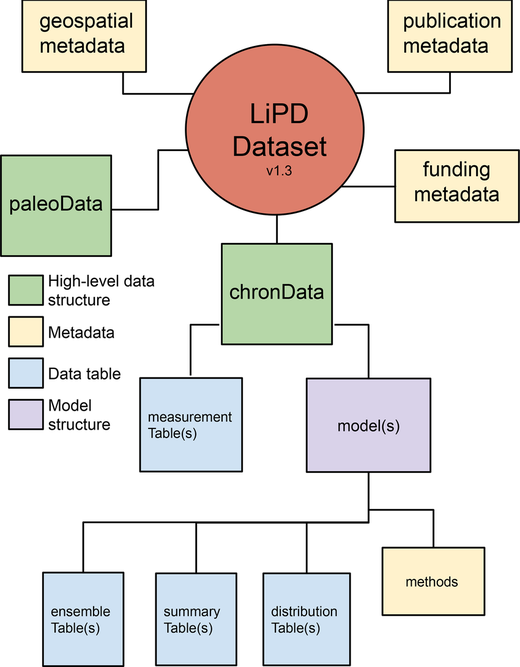

*Structure of a LiPD dataset (McKay et al., 2021). The paleo-data part mirrors the chronology part shown here.*

## 1b. Load all coral files into one table

`LiPD()` reads every `.lpd` file in the folder, and `get_timeseries(...)` turns them into a **pandas table (a "DataFrame") where one row = one time series**. A single coral dataset can give several rows (for example one row for δ¹⁸O, one for Sr/Ca and one for its year axis).

This cell can take a while the first time. The first line, `%%capture load_log`, is a Jupyter command that hides the long list of progress messages (they are stored in `load_log` if you ever want to see them).

In [ ]:
%%capture load_log
lipd = LiPD()
lipd.load_from_dir(str(CORAL_DIR))                       # read every .lpd file
ts_dict, df = lipd.get_timeseries(lipd.get_all_dataset_names(), to_dataframe=True)

We sort the rows by name (so the table is in the same order on every computer), then check how many datasets we loaded and the size of the table (rows, columns).

In [ ]:
df = df.sort_values(["dataSetName", "paleoData_TSid"]).reset_index(drop=True)
n_datasets = len(lipd.get_all_dataset_names())
assert n_datasets == 179, f"Expected 179 datasets but loaded {n_datasets}: check that the data folder is complete (see README)."
print("Datasets loaded:", n_datasets)
print("Table shape (rows, columns):", df.shape)

## 1c. Look at the table

The table has many columns. We show only the few we need, for the first five rows. Note that the columns `year` and `paleoData_values` contain whole arrays (the time axis and the measurements of each record).

In [ ]:
cols = ["dataSetName", "archiveType", "paleoData_variableName",
        "geo_meanLat", "geo_meanLon", "geo_ocean", "minYear", "maxYear"]
df[cols].head()

Which variables are in the database? `value_counts()` counts how many rows have each value. (Rows called `year` are the time axes, stored as their own series; we will ignore them.)

In [ ]:
df["paleoData_variableName"].value_counts()

And in which ocean basins are the records?

In [ ]:
df["geo_ocean"].value_counts()

## 1d. Select records with a filter

To keep only some rows we write a **condition** for each row (True/False) and pass it to the table: `df[condition]`. Conditions can be combined with `&` (and) or `|` (or); each condition goes in its own brackets.

Here we keep δ¹⁸O records that are **long**: they start before 1890 and end after 1980, so they cover the period we will compare with instrumental SST in Part 2.

In [ ]:
is_d18o = df["paleoData_variableName"] == "d18O"
is_long = (df["minYear"] < 1890) & (df["maxYear"] > 1980)

df_long = df[is_d18o & is_long]
print("Long d18O records:", len(df_long))

### ⚠️ Always inspect what you selected

A filter on the variable name is **not enough**. What is a δ¹⁸O value? It is the ratio of ¹⁸O to ¹⁶O, given in per mil (‰) as a difference from a reference standard (for carbonate, the VPDB scale). Coral skeletons growing in warm tropical water contain less ¹⁸O than that standard, so their values are negative. A series that hovers around zero is a different kind of thing: probably an anomaly (a difference from an average), not a measurement of the skeleton. Let's look at the identifier (`paleoData_TSid`), the average value and the notes of each selected series.

In [ ]:
mean_value = df_long["paleoData_values"].apply(lambda v: np.nanmean(np.asarray(v, dtype=float)))
is_seawater = df_long["paleoData_TSid"].str.contains("_sw")

for label, means in [("other series", mean_value[~is_seawater]), ("'_sw' series", mean_value[is_seawater])]:
    print(f"Average values of the {len(means)} {label}: 10th-90th percentile {means.quantile(0.1):.2f} to {means.quantile(0.9):.2f} permil")
print("Identifiers ending in '_sw':", ", ".join(df_long.loc[is_seawater, "paleoData_TSid"]))

notes = df_long.loc[is_seawater, "paleoData_notes"].dropna().astype(str)
notes = notes[notes.str.contains("sw|seawater|anomal", case=False)]     # notes that say what the series is
if len(notes) > 0:
    print(f"Notes of {df_long.loc[notes.index[0], 'paleoData_TSid']}: {notes.iloc[0][:200]}")

These `_sw` series are **not coral measurements** but reconstructed **seawater δ¹⁸O** (δ¹⁸O<sub>sw</sub>), calculated from paired coral δ¹⁸O and Sr/Ca. How can we tell? The identifier is the reliable marker; the average value is a clue that something is different (compare the two ranges printed above); the notes field confirms it when present. None of these is a flag by itself, which is why we look at several things. We remove these series by their identifier.

In [ ]:
df_long = df_long[~is_seawater]
print("Long coral d18O records (seawater series removed):", len(df_long))
df_long["geo_ocean"].value_counts()

## 1e. Map the selected records

A small map function: one dot per record, coloured by ocean basin, centred on the Pacific. We reuse it in *Your turn*.

In [ ]:
# Colour-blind-safe colours (Okabe-Ito palette), one per ocean basin
OCEAN_COLOURS = {"Pacific Ocean": "#0072B2", "Indian Ocean": "#E69F00", "Atlantic Ocean": "#009E73",
                 "Red Sea": "#CC79A7", "Bay of Bengal": "#56B4E9"}

def plot_record_map(table, title):
    # One dot per row of `table`, coloured by ocean basin, on a Pacific-centred world map
    fig = plt.figure(figsize=(11, 5))
    ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
    ax.set_global()
    ax.add_feature(cfeature.LAND, facecolor="0.88")
    ax.coastlines(linewidth=0.5)
    for ocean, group in table.groupby("geo_ocean"):
        ax.scatter(group["geo_meanLon"], group["geo_meanLat"], transform=ccrs.PlateCarree(),
                   s=45, color=OCEAN_COLOURS.get(ocean, "0.4"), edgecolor="black", linewidth=0.5,
                   label=f"{ocean} ({len(group)})")
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="Ocean (number of records)")
    ax.set_title(title)
    plt.show()

plot_record_map(df_long, "Long coral δ¹⁸O records (start before 1890, end after 1980)")

Most long records are in the tropical Pacific and Indian Oceans: partly where reef corals grow, but mostly where researchers have drilled cores. The map shows our *sampling*, not the whole ocean.

---
### ✏️ Your turn

1. How many **Sr/Ca** records are in the database (any length)?
2. How many **coral d18O** records (seawater `_sw` series excluded) are there in the **Atlantic Ocean**?
3. Map your selection with `plot_record_map(...)`.

Edit the words in quotes below and re-run (exact spellings are in the `value_counts()` outputs above).

<details><summary>Show the answer code</summary>

```python
not_sw = ~df["paleoData_TSid"].str.contains("_sw")
df_mine = df[df["paleoData_variableName"] == "Sr/Ca"]                                                # question 1
df_mine = df[(df["paleoData_variableName"] == "d18O") & (df["geo_ocean"] == "Atlantic Ocean") & not_sw]  # question 2
```
</details>

In [ ]:
# YOUR TURN: change "d18O" and "Pacific Ocean" to answer the questions above
not_sw = ~df["paleoData_TSid"].str.contains("_sw")          # leave out seawater d18O series
df_mine = df[(df["paleoData_variableName"] == "d18O") & (df["geo_ocean"] == "Pacific Ocean") & not_sw]
print("Records selected:", len(df_mine))
plot_record_map(df_mine, "My selection")

---
# Part 2 – PCA and EOF: do corals record ENSO?

## 2a. Hypothesis and the idea behind PCA/EOF

**ENSO** (El Niño–Southern Oscillation) is the largest year-to-year climate signal on Earth. Every 2–7 years the central and eastern tropical Pacific warms (El Niño) or cools (La Niña) by about 1–3 °C, and the rain belt over the western Pacific shifts east or west with it. ENSO peaks in boreal winter, so we look at **December–January–February (DJF)** means.

Coral δ¹⁸O responds to both **water temperature** and **seawater δ¹⁸O** (which follows rainfall and salinity). So corals across the Pacific should "feel" ENSO. **Hypothesis: the main shared pattern of variability in the coral δ¹⁸O records is ENSO, and it should match the main pattern of observed SST.**

**PCA in plain words.** Imagine many records that wiggle up and down. PCA looks for the single combination of records that captures the most shared wiggling, then the next one (uncorrelated with the first), and so on. Each such **mode** has two parts:

* a **principal component (PC)**: a *time series* saying how strongly the mode is present each year;
* a set of **loadings** (one number per record): how much, and with which sign, each record follows that PC. When the "records" are grid cells of a map, the loadings form a *map*, called an **EOF** (empirical orthogonal function).

PCA and EOF analysis are the same maths: "PCA" is the statistics word, "EOF" the climate-science word for PCA on a map of data. Two things to remember:

* **Variance explained**: each mode explains a percentage of the total variability. A large first percentage means one pattern dominates.
* **The sign is arbitrary**: a mode can come out "upside down" (PC × −1 and loadings × −1 is the same answer). We are free to flip it to make plots easier to compare.

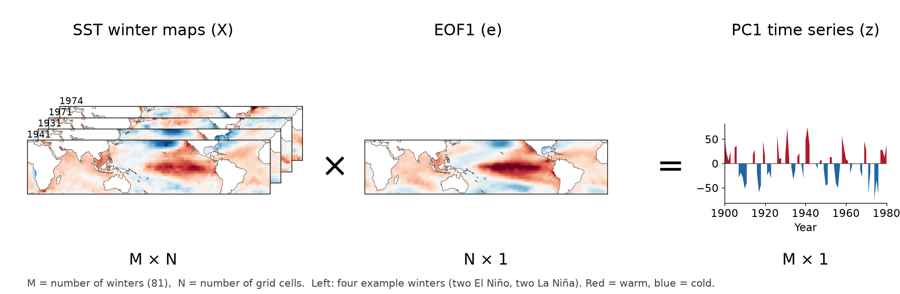

*Schematic of EOF analysis with this practical's own SST data: a data matrix X (winters × grid cells) is projected on a spatial pattern (EOF1, e) to give a time series (PC1, z). Left: four example winters.*

## 2b. Prepare the coral records, step by step

PCA needs every record on the **same** set of years, with no gaps, and on a comparable scale. Each step below has one reason.

**Step 1 – keep high-resolution records.** We start from the long coral δ¹⁸O records of Part 1 (seawater series already removed) and keep those with at least ~4 samples per year (median spacing ≤ 0.25 yr, with a tiny tolerance for rounding in the stored years), so that we can compute a winter mean. We print what is dropped, so nothing disappears silently.

In [ ]:
spacing = df_long["year"].apply(lambda t: np.nanmedian(np.abs(np.diff(np.asarray(t, float)))))  # median years between samples
is_fine = spacing <= 0.25 + 1e-3
print("Dropped (too coarse):", ", ".join(f"{n} ({s:.2f} yr)" for n, s in zip(df_long.loc[~is_fine, "dataSetName"], spacing[~is_fine])))
df_corals = df_long[is_fine]
assert df_corals["dataSetName"].is_unique                  # one series per dataset name
print("High-resolution long coral d18O records:", len(df_corals))
df_corals["geo_ocean"].value_counts()

**Step 2 – turn each row into a pyleoclim `GeoSeries`** (a time series that also knows its location), and collect them in a `MultipleGeoSeries`. Each series is labelled with its dataset name (unique in this selection).

In [ ]:
series = []
for _, row in df_corals.iterrows():
    series.append(pyleo.GeoSeries(
        time=row["year"], value=row["paleoData_values"],
        time_name="Year", time_unit="year CE",
        value_name="δ¹⁸O", value_unit="‰ VPDB",
        lat=row["geo_meanLat"], lon=row["geo_meanLon"],
        label=row["dataSetName"], auto_time_params=False, verbose=False))

corals = pyleo.MultipleGeoSeries(series, time_unit="year CE")
print("Series in the collection:", len(corals.series_list))

**Step 3 – remove slow trends.** Long-term drifts (e.g. 20th-century warming, or slow changes in the coral itself) would otherwise dominate the PCA. We remove them with EMD detrending (it subtracts the slowest component of each record), so the PCA focuses on year-to-year changes.

In [ ]:
corals_dt = corals.detrend(method="emd")

**Step 4 – make a winter (DJF) mean for every year.** The function below averages the December, January and February samples. December belongs to the **next** year, so "DJF 1998" = Dec 1997 + Jan 1998 + Feb 1998 (the same convention as the SST file we use later). The same function is in `paleo_helpers.py` for the group tasks.

In [ ]:
def djf_mean(g, min_obs=1):
    # Winter (Dec-Jan-Feb) mean of a GeoSeries; December counts towards the NEXT year
    t = np.asarray(g.time, float)
    x = np.asarray(g.value, float)
    year = np.floor(t)
    month = np.floor((t - year) * 12) + 1                    # 1 = January ... 12 = December
    keep = np.isin(month, [12, 1, 2]) & np.isfinite(x)
    season_year = year[keep] + (month[keep] == 12)           # Dec 1997 -> winter 1998
    s = pd.Series(x[keep]).groupby(season_year).agg(["mean", "count"])
    s = s[s["count"] >= min_obs]
    return pyleo.GeoSeries(time=s.index.values, value=s["mean"].values,
                           time_name="Year", time_unit="year CE", value_name="δ¹⁸O", value_unit="‰ VPDB",
                           lat=g.lat, lon=g.lon, label=g.label, auto_time_params=False, verbose=False)

corals_djf = pyleo.MultipleGeoSeries([djf_mean(g) for g in corals_dt.series_list], time_unit="year CE")

**Check the winter means.** Not every record is monthly: for some, a "DJF mean" is really one sample per winter, and some winters are missing. This cell lists those records (samples per winter on average over 1900–1980, and winters present out of 81).

In [ ]:
rows = []
for raw, win in zip(corals_dt.series_list, corals_djf.series_list):
    t = np.asarray(raw.time, float)
    month = np.floor((t - np.floor(t)) * 12) + 1
    n_djf = (np.isin(month, [12, 1, 2]) & (t > 1899.9) & (t < 1980.2)).sum()        # Dec 1899 ... Feb 1980
    yrs = np.round(win.time)                                                          # winter labels (whole years)
    n_win = ((yrs >= 1900) & (yrs <= 1980)).sum()
    rows.append({"record": raw.label, "samples per winter": round(n_djf / 81, 1), "winters present (of 81)": n_win})
djf_check = pd.DataFrame(rows)
djf_check[(djf_check["samples per winter"] < 1.5) | (djf_check["winters present (of 81)"] < 81)]

For the records with about one sample per winter, the "DJF mean" is a single measurement, and because month stamps differ between records the DJF window is only good to about ±1 month. Missing winters (see the last column) are filled by interpolation in the next step.

**Step 5 – put all records on the same years.** `common_time` interpolates every record onto one annual axis (`step=1`) from 1900 to 1980, the period when all records overlap.

In [ ]:
corals_ct = corals_djf.common_time(method="interp", step=1, start=1900, stop=1980)
years_coral = corals_ct.series_list[0].time
print("First and last year:", years_coral[0], years_coral[-1], "| number of years:", len(years_coral))

**Step 6 – standardise, and flip the sign.** Each record is rescaled to mean 0 and standard deviation 1, so that records with large δ¹⁸O swings do not dominate just because of their units. Then we multiply every record by −1. Coral δ¹⁸O **falls** when the water gets warmer or wetter, so **−δ¹⁸O rises** when it gets warmer or wetter, just like SST: from now on "up" (and red on the maps) means warm/wet for both corals and SST. (Remember: in the raw data the sign is the opposite, lower δ¹⁸O = warmer/wetter.)

In [ ]:
corals_std = corals_ct.standardize()
flipped = []
for s in corals_std.series_list:
    f = s.copy()
    f.value = -s.value                       # -d18O: up = warm/wet, like SST
    f.value_name = "-δ¹⁸O"
    flipped.append(f)
corals_ready = pyleo.MultipleGeoSeries(flipped, time_unit="year CE")

## 2c. PCA on the corals

The PCA itself is a single command. The result `pca` contains, among other things:

* `pca.pctvar` – the percentage of variance explained by each mode;
* `pca.pcs` – the PCs (one column per mode, one row per year);
* `pca.eigvecs` – the loadings (one column per mode, one row per coral record).

In [ ]:
pca = corals_ready.pca()
print("Variance explained by the first 5 modes (%):", np.round(pca.pctvar[:5], 1))

A **scree plot** shows the variance explained by each mode. A big first bar followed by a sharp drop would mean one dominant pattern; a slow decline means the variability is spread over many modes.

In [ ]:
n_show = 10
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(np.arange(1, n_show + 1), pca.pctvar[:n_show], color="#0072B2")
ax.set_xticks(np.arange(1, n_show + 1))
ax.set_xlabel("Mode number")
ax.set_ylabel("Variance explained (%)")
ax.set_title("Coral PCA (−δ¹⁸O): scree plot")
plt.show()

Coral PC1 stands out from the other modes (about twice mode 2), but it explains only a **modest share** of the total variance (well under a quarter); the rest is spread over many small modes. Coral records are noisy and each site also has local signals, so this is normal. Let's look at PC1 anyway: its time series, and its loadings on a map.

A **loading** tells you how a record relates to the PC: a large positive loading means "this record goes up when PC1 goes up", a large negative loading means "this record goes down when PC1 goes up", and a loading near zero means the record does not share this pattern. The cell also defines two small map functions that we reuse later.

In [ ]:
def tropical_map(ax):
    # Pacific-centred map of the 40S-40N band with land and coastlines
    ax.set_extent([-180, 180, -40, 40], crs=ccrs.PlateCarree(central_longitude=180))
    ax.add_feature(cfeature.LAND, facecolor="0.88", zorder=2)
    ax.coastlines(linewidth=0.5, zorder=3)

def plot_dots(ax, values, vmax):
    # one dot per coral, coloured on the same red-blue scale as the SST maps
    return ax.scatter(coral_lon, coral_lat, c=values, cmap="RdBu_r", vmin=-vmax, vmax=vmax, s=80,
                      edgecolor="black", linewidth=0.8, transform=ccrs.PlateCarree(), zorder=5)

coral_pc1 = pca.pcs[:, 0]                       # time series of mode 1
coral_load1 = np.asarray(pca.eigvecs)[:, 0]     # one loading per coral record
coral_lat = np.array([s.lat for s in corals_ready.series_list])
coral_lon = np.array([s.lon for s in corals_ready.series_list])

fig = plt.figure(figsize=(12, 7))
ax1 = fig.add_subplot(2, 1, 1, projection=ccrs.PlateCarree(central_longitude=180))
tropical_map(ax1)
dots = plot_dots(ax1, coral_load1, np.abs(coral_load1).max())
fig.colorbar(dots, ax=ax1, shrink=0.8, label="PC1 loading (unitless)")
ax1.set_title(f"Coral PC1 loadings ({pca.pctvar[0]:.1f}% of variance; sign not yet fixed)")

ax2 = fig.add_subplot(2, 1, 2)
ax2.plot(years_coral, coral_pc1, color="black", lw=1.5)
ax2.axhline(0, color="0.6", lw=0.8)
ax2.set_xlabel("Year (CE)")
ax2.set_ylabel("Coral PC1 (unitless)")
ax2.set_title("Coral PC1 time series (sign not yet fixed)")
plt.tight_layout()
plt.show()

**What to look for:** the loadings are not all the same colour. Corals in the western Pacific and in the central Pacific load with **opposite signs**, i.e. coral PC1 is a *see-saw* (dipole) between regions, not a uniform pattern. Which side is red depends on the arbitrary sign of PC1; we fix it in 2f by comparing with SST. Is this ENSO? To find out we need the same analysis on real SST observations.

## 2d. Observed sea-surface temperature (netCDF + xarray)

Gridded climate data are usually stored as **netCDF** files: a set of variables (here `sst`) on shared **dimensions** (`time`, `lat`, `lon`), plus **coordinates** (the actual values of time, latitude and longitude) and **attributes** (units, notes). The `xarray` library reads them into a `Dataset` that keeps all of this together.

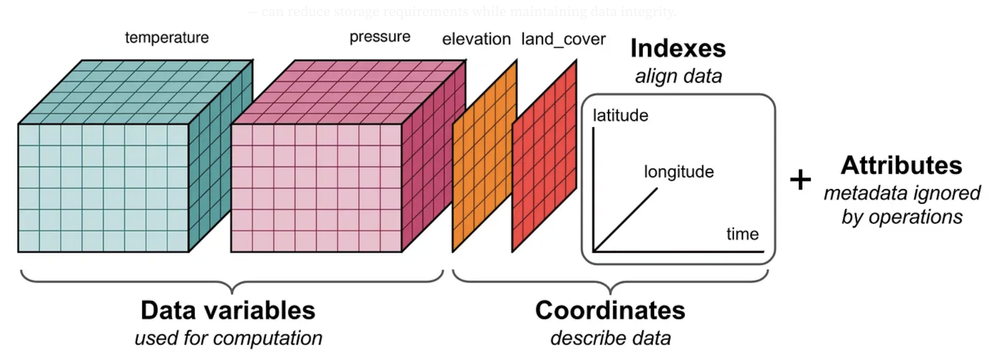

*Structure of a netCDF dataset (image: S. Hoyer, xarray, Apache 2.0).*

Our file is **HadISST1** (Met Office Hadley Centre; Rayner et al., 2003), already turned into DJF means for the whole tropical band 40°S–40°N, all longitudes (longitudes run 0–360), so that every coral site sits inside the SST field. Let's open it and print its summary.

In [ ]:
ds = xr.open_dataset(SST_FILE)
ds

Things to notice in the summary: the three **dimensions** and their sizes; `time` is stamped on 1 January of each DJF year (so `1998-01-01` = DJF 1998); the `sst` units are °C; and the `note` attribute says that any grid cell with gaps during 1900–1980 has been blanked (NaN) for all years, so the EOF sees only complete cells (they appear white on the maps below, together with land).

Next we select the `sst` variable and the same years as the corals with `.sel(...)`.

In [ ]:
sst = ds["sst"].sel(time=slice("1900", "1980"))
years_sst = sst["time"].dt.year.values
print("Shape (time, lat, lon):", sst.shape, "| years", years_sst[0], "to", years_sst[-1])
print("Blank grid cells (land or gaps): about", round(float(sst.isel(time=0).isnull().mean()) * 100), "%")

**Area weights.** On a latitude–longitude grid, cells near the poles are smaller than cells at the equator, but each counts as one data point. We give each cell a weight of √cos(latitude) so that its *variance* is weighted by cos(latitude), i.e. by its area. (Within 40° of the equator the effect is modest, but it is good practice.)

In [ ]:
weights = np.sqrt(np.cos(np.deg2rad(sst["lat"])))

## 2e. EOF analysis of SST with xeofs

`xe.single.EOF` sets up the analysis; `center=True` first removes each cell's 1900–1980 mean (so we analyse **anomalies**), and `fit(..., dim="time")` says that *time* is the dimension along which things vary. Then:

* `explained_variance_ratio()` – the fraction of variance per mode;
* `components()` – the **EOFs** (maps; dimensions mode, lat, lon);
* `scores()` – the **PCs** (time series; dimensions mode, time).

In [ ]:
model = xe.single.EOF(n_modes=4, center=True)
model.fit(sst, dim="time", weights=weights)

sst_var = model.explained_variance_ratio() * 100
sst_eofs = model.components()
sst_pcs = model.scores()
print("Variance explained by SST modes 1-4 (%):", np.round(sst_var.values, 1))

Mode 1 explains the largest share (about 30%), about twice mode 2. Is mode 1 ENSO? A common ENSO index is the **Niño3.4** index: the average SST in the box 5°S–5°N, 170°W–120°W (190°E–240°E; a simple unweighted box mean). We correlate it with SST PC1 and, because the sign of a PC is arbitrary, flip mode 1 if needed so that **positive PC1 = warm Niño3.4 = El Niño**. To find out what mode 2 is, we orient it so that PC2 rises with time (red = warming), and correlate PC2 with time (a trend), with Niño3.4, and with simple box means over the tropical Atlantic (20°S–20°N, 60°W–10°W) and Indian Ocean (20°S–20°N, 40°E–110°E).

In [ ]:
nino34 = sst.sel(lat=slice(-5, 5), lon=slice(190, 240)).mean(["lat", "lon"])
atlantic = sst.sel(lat=slice(-20, 20), lon=slice(300, 350)).mean(["lat", "lon"])
indian = sst.sel(lat=slice(-20, 20), lon=slice(40, 110)).mean(["lat", "lon"])

sign = np.sign(xr.corr(sst_pcs.sel(mode=1), nino34)).item()   # +1 or -1
sst_pc1 = sst_pcs.sel(mode=1) * sign
sst_eof1 = sst_eofs.sel(mode=1) * sign
sign2 = np.sign(np.corrcoef(sst_pcs.sel(mode=2), years_sst)[0, 1])   # orient mode 2 so that PC2 rises with time
sst_pc2 = sst_pcs.sel(mode=2) * sign2
sst_eof2 = sst_eofs.sel(mode=2) * sign2

print("Sign applied to mode 1:", int(sign))
print("PC1: r with Niño3.4 =", round(xr.corr(sst_pc1, nino34).item(), 2),
      "| r with time =", round(np.corrcoef(sst_pc1, years_sst)[0, 1], 2))
print("PC2: r with time =", round(np.corrcoef(sst_pc2, years_sst)[0, 1], 2),
      "| with Niño3.4 =", round(xr.corr(sst_pc2, nino34).item(), 2),
      "| with tropical Atlantic =", round(xr.corr(sst_pc2, atlantic).item(), 2),
      "| with Indian Ocean =", round(xr.corr(sst_pc2, indian).item(), 2))

Now the picture: EOF1 and EOF2 (maps, same red-blue scale with red = positive) and their PCs.

In [ ]:
def plot_field(ax, field, vmax):
    # add_cyclic_point repeats the first longitude at 360 so there is no gap at the map seam
    data, lon = add_cyclic_point(field.values, coord=field["lon"].values)
    return ax.pcolormesh(lon, field["lat"], data, cmap="RdBu_r", vmin=-vmax, vmax=vmax,
                         shading="auto", transform=ccrs.PlateCarree())

fig = plt.figure(figsize=(14, 6.5))
grid = fig.add_gridspec(2, 2, width_ratios=[1.8, 1])
for row, (eof, pc, pc_title) in enumerate([(sst_eof1, sst_pc1, "SST PC1 (positive = El Niño)"),
                                           (sst_eof2, sst_pc2, "SST PC2 (oriented to rise with time)")]):
    k = row + 1
    ax_map = fig.add_subplot(grid[row, 0], projection=ccrs.PlateCarree(central_longitude=180))
    tropical_map(ax_map)
    im = plot_field(ax_map, eof, float(np.abs(eof).quantile(0.99)))   # 99th percentile: a few coastal extremes do not wash out the colours
    fig.colorbar(im, ax=ax_map, shrink=0.85, label="EOF weight")
    ax_map.set_title(f"SST EOF{k} ({sst_var.sel(mode=k).item():.1f}% of variance)")
    ax_pc = fig.add_subplot(grid[row, 1])
    ax_pc.plot(years_sst, pc, color="black", lw=1.2)
    ax_pc.axhline(0, color="0.6", lw=0.8)
    ax_pc.set_title(pc_title)
    ax_pc.set_ylabel("PC score")
ax_pc.set_xlabel("Year (CE)")
plt.tight_layout()
plt.show()

**What does EOF1 look like?** Strong warm anomalies (red) along the equatorial central and eastern Pacific, surrounded by anomalies of the opposite sign (blue) in the western Pacific and the subtropics of both hemispheres, in a "horseshoe" shape; the Indian Ocean warms too (weaker red). This is the classic **El Niño pattern**, and its PC1 correlates very strongly with the Niño3.4 index and has almost no trend (printed above).

**What is EOF2?** Its map is the same sign over most of the band and PC2 rises through the century (it correlates with time, not with Niño3.4, printed above): mode 2 is mostly the slow, widespread warming. EOF2 is not uniform, though: the eastern equatorial Pacific does not warm (pale blue). A likely explanation, suggested by model experiments, is that land warms faster than the ocean; this land–sea contrast shifts the tropical rain belt north, shifts convection westward over the western Pacific and strengthens the subtropical high-pressure system over the South Pacific. Together these strengthen the winds along the equator and off Peru, which increases evaporation and upwelling in the east, so this "cold tongue" cools instead of warming (Günther, Kang and Kaspi, 2026).

**One more sanity check.** The EOF was learned from 1900–1980 only. We can *project* the later years (1981–2000, which are also in the file) onto the same pattern with `model.transform(...)` and list the years with the strongest positive PC1. If mode 1 is really ENSO, famous El Niño winters should come out on top.

In [ ]:
pc1_all = model.transform(ds["sst"]).sel(mode=1) * sign      # PC1 for every year in the file, 1900-2000
pc1_all = pc1_all.assign_coords(year=pc1_all["time"].dt.year).swap_dims({"time": "year"})
print("Five strongest positive PC1 years (DJF), 1900-2000:")
print(pc1_all.sortby(pc1_all, ascending=False)["year"].values[:5])

The two largest values are the DJF winters of 1983 and 1998, i.e. the well-known 1982/83 and 1997/98 El Niños, even though the model never saw those years. SST mode 1 is ENSO.

## 2f. Do the corals see ENSO? Coral PC1 vs SST PC1

To compare the two PCs we must line them up **by year label**, not by position. We give both a `year` coordinate and let xarray keep only the years present in both (`xr.align`), and compute the **Pearson correlation** `r` with its `p`-value. The sign of coral PC1 is arbitrary too: if r comes out negative we flip **both** the coral PC1 and its loadings, so that positive coral PC1 = El Niño-like, like SST PC1.

In [ ]:
coral_pc1_da = xr.DataArray(coral_pc1, coords={"year": years_coral.astype(int)}, dims="year")
sst_pc1_da = sst_pc1.assign_coords(year=sst_pc1["time"].dt.year).swap_dims({"time": "year"})
coral_al, sst_al = xr.align(coral_pc1_da, sst_pc1_da, join="inner")    # keep only years present in both

common_years = coral_al["year"].values
coral_sel, sst_sel = coral_al.values, sst_al.values

r, p = stats.pearsonr(coral_sel, sst_sel)
if r < 0:
    coral_sel, coral_load1, r = -coral_sel, -coral_load1, -r
    print("Coral PC1 came out upside down: flipped PC1 and its loadings.")
else:
    print("Coral PC1 already points the same way as SST PC1: no flip needed.")

print("Years compared:", len(common_years), f"({common_years[0]}-{common_years[-1]})")
print(f"Coral PC1 vs SST PC1: r = {r:.2f}, p = {p:.1e}")

The p-value assumes independent years; neighbouring years are partly alike, so the evidence is a bit weaker than this tiny p suggests, but with r this large the link is clear.

Now the key figure: the SST EOF1 map with the coral PC1 loadings as dots on top (both on the same red-blue scale: red = goes up in El Niño winters), and the two PCs overlaid (both standardised so they share one axis).

In [ ]:
def standardise(x):
    return (x - x.mean()) / x.std()

fig = plt.figure(figsize=(13, 8.5))
ax1 = fig.add_subplot(2, 1, 1, projection=ccrs.PlateCarree(central_longitude=180))
tropical_map(ax1)
im = plot_field(ax1, sst_eof1, float(np.abs(sst_eof1).max()))
dots = plot_dots(ax1, coral_load1, np.abs(coral_load1).max())
fig.colorbar(im, ax=ax1, shrink=0.75, pad=0.01, label="SST EOF1 weight (shading)")
fig.colorbar(dots, ax=ax1, shrink=0.75, pad=0.02, label="Coral PC1 loading (dots)")
ax1.set_title("SST EOF1 (shading) and coral PC1 loadings (dots); red = up in El Niño winters")

ax2 = fig.add_subplot(2, 1, 2)
ax2.plot(common_years, standardise(sst_sel), color="#D55E00", lw=2, label="SST PC1 (HadISST1)")
ax2.plot(common_years, standardise(coral_sel), color="#0072B2", lw=2, label="Coral PC1 (−δ¹⁸O)")
ax2.axhline(0, color="0.6", lw=0.8)
ax2.set_xlabel("Year (CE, DJF)")
ax2.set_ylabel("Standardised PC")
ax2.set_title(f"r = {r:.2f}, p = {p:.1e}, n = {len(common_years)} years")
ax2.legend(loc="upper left", ncol=2)
plt.tight_layout()
plt.show()

**Why do the dots have different colours?** Coral δ¹⁸O responds to water temperature **and** to the δ¹⁸O of the seawater, which follows rainfall and salinity. During El Niño the central and eastern Pacific warm and the tropical rain belt shifts east, so corals in the centre and in the west respond with opposite signs (on our −δ¹⁸O scale: mostly red in the centre, blue in the west). That is why coral PC1 is a west-versus-central see-saw rather than a uniform pattern. Group Task 1 looks at individual sites.

## 2g. Spectral analysis: at which periods do the two PCs vary?

So far we worked in the **time domain**: one value for each year. Spectral analysis works in the **frequency domain**: it splits a time series into a sum of sine waves with different periods, and the **power spectrum** shows how much of the variance each period carries, like hearing which instruments are loudest in an orchestra. The **period** of a wave is 1/frequency (here in years). Climate has memory, so purely random variability (**red noise**) already puts most of its variance at long periods; we therefore compare peaks with a red-noise line (dashed: the level that random series with the same memory rarely exceed). With 81 winters we cannot judge periods longer than about 40 years. A spectrum does not care about the sign of a series.

For a gentle, hands-on introduction to spectral analysis (sine waves, windows, red noise) see the optional notebook `Spectral_analysis_primer.ipynb` in this folder.

In [ ]:
# a taper (window) reduces edge effects; see the optional primer
N_SIM = 1000                                   # number of red-noise series for the significance test

def spectrum(x):
    # periodogram of an annual series (Hann window, linear detrend); returns period (yr) and power
    f, power = periodogram(x, fs=1.0, window="hann", detrend="linear", axis=-1)
    return 1 / f[1:], power[..., 1:]           # drop frequency 0 (infinite period)

def red_noise_95(x, seed=42):
    # pointwise 95th percentile of the spectra of N_SIM AR(1) series with the same lag-1 autocorrelation
    rng = np.random.default_rng(seed)          # fixed seed: same answer every time, whatever the call order
    a = np.corrcoef(x[:-1], x[1:])[0, 1]
    noise = rng.standard_normal((N_SIM, len(x)))
    sims = np.zeros_like(noise)
    sims[:, 0] = noise[:, 0]
    for t in range(1, len(x)):
        sims[:, t] = a * sims[:, t - 1] + np.sqrt(1 - a**2) * noise[:, t]
    sims = sims / sims.std(axis=1, keepdims=True) * x.std()     # same variance as the data
    sim_power = spectrum(sims)[1]
    return a, np.percentile(sim_power, 95, axis=0), sim_power

spec_series = {"SST PC1": (standardise(sst_sel), "#D55E00"), "Coral PC1 (−δ¹⁸O)": (standardise(coral_sel), "#0072B2")}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (name, (x, colour)) in zip(axes, spec_series.items()):
    period, power = spectrum(x)
    a, null95, sim_power = red_noise_95(x)
    ax.axvspan(2, 7, color="0.9", label="ENSO band (2–7 yr)")
    ax.semilogx(period, power, color=colour, lw=2, label=name)
    ax.semilogx(period, null95, color="0.4", ls="--", label="red noise, 95th percentile")
    ax.set_xlim(2, 40)
    ax.set_xticks([2, 3, 5, 7, 10, 20, 40]); ax.set_xticklabels([2, 3, 5, 7, 10, 20, 40]); ax.minorticks_off()
    ax.set_xlabel("Period (years)")
    ax.set_title(f"{name}  (lag-1 autocorrelation {a:.2f})")

    in_band = (period >= 2) & (period <= 7)
    k = np.argmax(np.where(in_band, power, -np.inf))           # highest peak inside the ENSO band
    outside = period[~in_band & (power > null95)]               # periods outside 2-7 yr above the line
    print(f"{name}: highest peak in the ENSO band at {period[k]:.1f} yr, {power[k] / null95[k]:.1f} times the red-noise line; "
          f"periods outside 2-7 yr above the line: {'none' if len(outside) == 0 else np.round(outside, 1)}")
axes[0].set_ylabel("Power (standardised units² per cycle/yr)")
handles = [h for ax in axes for h in ax.get_legend_handles_labels()[0]]
labels = [l for ax in axes for l in ax.get_legend_handles_labels()[1]]
unique = dict(zip(labels, handles))
fig.legend(unique.values(), unique.keys(), loc="lower center", ncol=4, fontsize=11)
plt.tight_layout(rect=[0, 0.1, 1, 1])
plt.show()

**What the figure shows.** Both series have their main cycle at about 5–6 years, inside the ENSO band, and nothing else comes close: the peak is roughly twice the red-noise line, so both PCs carry a cycle in the ENSO band. With only 81 winters this is suggestive rather than conclusive, because red noise can cross the line by chance somewhere in the band. And the two PCs are strongly related (r in 2f), so they are not independent evidence.

## 2h. Conclusions and caveats

**Conclusions**

* SST mode 1 (40°S–40°N) is **ENSO**: about 30% of the variance, very strongly correlated with Niño3.4, and it picks out the 1982/83 and 1997/98 El Niños. Mode 2 is mostly the warming trend.
* Coral PC1 (−δ¹⁸O) correlates strongly with SST PC1 over 1900–1980, as a **west-vs-central Pacific dipole**: the corals record ENSO.
* Both PCs have their main cycle at about 5–6 years, inside the ENSO band and roughly twice the red-noise line; with 81 winters this is suggestive, not conclusive.

**Caveats**

* The records are sparse and noisy: coral PC1 explains only a modest share of their variance.
* δ¹⁸O mixes temperature and seawater δ¹⁸O (rainfall/salinity); paired Sr/Ca would help separate them.
* Several records give a single sample per winter, and some winters were filled by interpolation.
* Variable names can hide different quantities (the seawater `_sw` series).
* PC/EOF signs are arbitrary, and we plotted −δ¹⁸O: lower raw δ¹⁸O = warmer/wetter.
* The SST file blanks cells with gaps, and HadISST before about 1950 is sparse and smoothed in the central Pacific.
* Only 81 winters: p-values assume independent years, and the spectral test is marginal.

## 2i. Next steps

The group tasks are in **`Group_tasks.ipynb`** (same folder); they use `paleo_helpers.py`, which does the same steps in fewer lines.

### Before class – checklist

* [ ] Run `python check_setup.py`, then this whole notebook once (restart the kernel and run all cells).
* [ ] The data check printed the number of LiPD files, and all maps show coastlines.
* [ ] Answer the *Your turn* questions in Part 1.
* [ ] Write down one sentence: what does a *loading* mean?

---
## Cheat sheet: the six pandas/xarray calls we used

| Call | What it does |
|---|---|
| `df[cols].head()` | show selected columns of the first 5 rows of a table |
| `df["col"].value_counts()` | count how many rows have each value |
| `df[(cond1) & (cond2)]` | keep only the rows where both conditions are True |
| `xr.open_dataset(path)` | open a netCDF file as an xarray `Dataset` |
| `da.sel(time=slice("1900", "1980"))` | select by coordinate values (here a range of years) |
| `da.mean(["lat", "lon"])` | average over one or more dimensions (e.g. a box mean) |

## Glossary

* **LiPD** – Linked Paleo Data: a standard file format that stores paleo data together with all their metadata.
* **PC** (principal component) – the time series of a mode: how strongly the pattern is present each year.
* **EOF** (empirical orthogonal function) – the spatial pattern (map) of a mode; PCA applied to gridded data.
* **Loading** – the weight of one record (or grid cell) in a mode: its sign and size say how it follows the PC.
* **Power spectrum** – how a series' variance is shared among cycles of different lengths (estimated here with a periodogram).
* **Period** – the length of one cycle, 1/frequency (here in years).
* **Red noise** – random variability with memory (each year partly resembles the last), which has more power at long periods even without any cycle; modelled here as AR(1).
* **Anomaly** – a value minus its long-term mean (e.g. SST minus the 1900–1980 average).
* **DJF** – December–January–February mean; December counts towards the following year.
* **δ¹⁸O** – ratio of ¹⁸O to ¹⁶O relative to a standard, in ‰ VPDB for coral carbonate; lower values mean warmer and/or wetter (fresher) water. In Part 2 we use **−δ¹⁸O** so that up = warm/wet, like SST.

## References

* McKay, N.P. and Emile-Geay, J., 2016. The Linked Paleo Data framework – a common tongue for paleoclimatology. *Climate of the Past*, 12, 1093–1100. https://doi.org/10.5194/cp-12-1093-2016
* McKay, N.P., Emile-Geay, J. and Khider, D., 2021. geoChronR – an R package to model, analyze, and visualize age-uncertain data. *Geochronology*, 3, 149–169. https://doi.org/10.5194/gchron-3-149-2021
* Walter, R.M. et al., 2023. The CoralHydro2k database: a global, actively curated compilation of coral δ¹⁸O and Sr/Ca proxy records of tropical ocean hydrology and temperature for the Common Era. *Earth System Science Data*, 15, 2081–2116. https://doi.org/10.5194/essd-15-2081-2023
* Rayner, N.A. et al., 2003. Global analyses of sea surface temperature, sea ice, and night marine air temperature since the late nineteenth century. *J. Geophys. Res.*, 108(D14), 4407. https://doi.org/10.1029/2002JD002670
* Emile-Geay, J. and Eshleman, J.A., 2013. Toward a semantic web of paleoclimatology. *Geochem. Geophys. Geosyst.*, 14, 457–469. https://doi.org/10.1002/ggge.20067
* Günther, M., Kang, S.M. and Kaspi, Y., 2026. Heating the land cools the eastern and equatorial Pacific. *Science Advances*, 12, eaeb7004. https://doi.org/10.1126/sciadv.aeb7004